# Lab 03 — Building a Cosmological Likelihood from Real Pantheon+ Supernovae

Theory for the lab: https://drive.google.com/drive/folders/1S5iSVmVUoWkfaXCHBevRXpv0tvsQKsym

**MSc Astrostatistics for Observational Cosmology · Week 3**  
**Contact time:** 4 hours · **Type:** formative practical and weekly checkpoint  
**Data:** published Pantheon+ / SH0ES standardized apparent magnitudes and the matching **statistical-only covariance**  
**Prerequisites:** Week 2 sampling and hypothesis testing; Week 3 likelihood and optimization lecture

> **Scientific question.** How can we infer the matter-density parameter from correlated supernova magnitudes, and why can we *not* independently determine the Hubble constant without absolute luminosity calibration?

**What you will produce:** a data audit, a correlated Gaussian likelihood, the profile maximum-likelihood estimate of $\Omega_m$, a likelihood interval, a numerical demonstration of the $H_0$–$M_B$ degeneracy, and residual diagnostics.

### Suggested timing

| Segment | Duration | Activity |
|:--|--:|:--|
| A | 35 min | data provenance, covariance, sampling unit |
| B | 35 min | derive the flat-$\Lambda$CDM distance model |
| C | 55 min | construct and analytically profile the Gaussian likelihood |
| Break | 10 min | — |
| D | 40 min | profile curve and likelihood interval |
| E | 35 min | $H_0$–$M_B$ non-identifiability experiment |
| F | 30 min | diagnostics, limitations and checkpoint |

**Rendering:** Equations in this notebook use standard Jupyter Markdown with `$$ ... $$` for centered mathematics and `$ ... $` for inline symbols. In Jupyter or Colab, run a Markdown cell with **Shift+Enter** to typeset it.


## A0. State the inference problem *before* running code

Copy and complete these five statements in your own words:

1. **Estimand:** what population/model quantity are we estimating?
2. **Observed data:** which table columns and covariance matrix are used?
3. **Generative model:** which physical and statistical assumptions connect observations to predictions?
4. **Uncertainty/selection:** what has been included, excluded, or conditioned on?
5. **Falsification diagnostic:** what plot or numerical check could reveal a failure?

**Prediction to record now:** If we replace the fixed convention $H_0=70$ by $H_0=73$ km s$^{-1}$ Mpc$^{-1}$, what should happen to $\widehat{\Omega}_m$ and $\widehat M_B$? Do not run the code before writing a prediction.


## A1. Reproducible environment and scientific-data policy

We will fit **real standardized magnitudes**, not a simulated Hubble diagram. The only numerical examples that do not use observations are deterministic *software checks* (such as a known quadratic minimum); those are never presented as supernova observations.

The notebook expects `numpy`, `pandas`, `scipy`, `matplotlib`, and `requests` (these are included in the course requirements). In Colab, uncomment the installation line if needed.


In [1]:
# In a fresh Colab session if dependencies are missing:
# %pip -q install numpy pandas scipy matplotlib requests

from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from scipy.linalg import cho_factor, cho_solve, solve_triangular
from scipy.optimize import minimize_scalar
from scipy.integrate import quad
from numpy.polynomial.legendre import leggauss

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "Pandas:", pd.__version__)


Python: 3.14.6
NumPy: 2.4.6 Pandas: 3.0.3


## A2. Data provenance: why the covariance matters

Official source: [Pantheon+ / SH0ES DataRelease](https://github.com/PantheonPlusSH0ES/DataRelease/tree/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR).

We use:

- `Pantheon+SH0ES.dat`: published standardized SN Ia magnitudes and redshifts.
- `Pantheon+SH0ES_STATONLY.cov`: the **$1701\times1701$** statistical covariance, in the *same row order* as the table.
- **Not for this fit:** `MU_SH0ES`, whose absolute magnitude zero point incorporates SH0ES distance-ladder calibration. We use `m_b_corr` instead.
- **Not as a likelihood:** `m_b_corr_err_DIAG`, provided for plotting rather than replacing the covariance matrix.

The official README explains that the statistical-only matrix *still contains off-diagonal terms* from repeat light-curve measurements of the same supernova. The statistical+systematic matrix additionally contains correlations associated with systematic uncertainties.

### Crucial row-order rule

If $I=(i_1,\ldots,i_n)$ denotes the selected **original row indices**, the covariance of the selected magnitudes is

$$
\boxed{
\mathbf C_{\rm selected}=\mathbf C_{\rm full}[I,I]
}
$$

(where the matrix operation means selecting **both** axes with the same ordered indices). Do **not** group by physical supernova ID or sort the table without identically transforming the covariance. Distinct rows for the same `CID` are allowed in the likelihood because their correlation is represented in $\mathbf C$.


In [2]:
BASE = (
    "https://raw.githubusercontent.com/PantheonPlusSH0ES/"
    "DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/"
)
URL_DATA = BASE + "Pantheon%2BSH0ES.dat"
URL_STAT = BASE + "Pantheon%2BSH0ES_STATONLY.cov"
URL_FULL = BASE + "Pantheon%2BSH0ES_STAT%2BSYS.cov"

CACHE = Path("data_cache/pantheon_plus")
CACHE.mkdir(parents=True, exist_ok=True)

def download_if_needed(url, path, timeout=180):
    """Use a local cache; require the official file if no local copy exists."""
    path = Path(path)
    if not path.is_file() or path.stat().st_size == 0:
        print("Downloading published data:", path.name)
        try:
            response = requests.get(url, timeout=timeout)
            response.raise_for_status()
            path.write_bytes(response.content)
        except requests.RequestException as exc:
            raise RuntimeError(
                f"Could not download {path.name}. Download it manually from the "
                f"Pantheon+ DataRelease and place it at {path.resolve()}"
            ) from exc
    return path

def load_table():
    path = download_if_needed(URL_DATA, CACHE / "Pantheon+SH0ES.dat")
    return pd.read_csv(path, sep=r"\s+")

def load_covariance(url=URL_STAT, filename="Pantheon+SH0ES_STATONLY.cov"):
    path = download_if_needed(url, CACHE / filename)
    # Official format: first line N; subsequent N*N scalar elements.
    with path.open("r") as stream:
        n = int(stream.readline().strip())
    flat = np.loadtxt(path, skiprows=1, dtype=float)
    if flat.size != n * n:
        raise ValueError(f"Covariance file says N={n}; found {flat.size} entries")
    matrix = flat.reshape((n, n))
    if not np.isfinite(matrix).all():
        raise ValueError("Covariance contains NaN or infinite entries")
    return matrix

sn = load_table()
print("Published table rows:", len(sn))
print("Unique physical SN IDs:", sn["CID"].nunique())
display(sn[["CID", "IDSURVEY", "zHD", "m_b_corr", "IS_CALIBRATOR"]].head())


Published table rows: 1701
Unique physical SN IDs: 1543


,CID,IDSURVEY,zHD,m_b_corr,IS_CALIBRATOR
0,2011fe,51,0.00122,9.74571,1
1,2011fe,56,0.00122,9.80286,1
2,2012cg,51,0.00256,11.47030,1
3,2012cg,56,0.00256,11.49190,1
4,1994DRichmond,50,0.00299,11.52270,0


In [5]:
C_all = load_covariance()
assert C_all.shape == (len(sn), len(sn)), "Table and covariance rows do not align"
assert np.allclose(C_all, C_all.T, atol=1e-7, rtol=1e-7)
print("Covariance dimensions and symmetry verified:", C_all.shape)


Covariance dimensions and symmetry verified: (1701, 1701)


## A3. Define the teaching sample *without destroying covariance alignment*

Our deliberately simple teaching cuts are

$$
\boxed{
\begin{aligned}
z_{{\rm HD},i} &> 0.01,\\
\mathrm{IS\_CALIBRATOR}_i &= 0,\\
\text{required columns} &\text{ are finite}.
\end{aligned}
}
$$

This is a transparent pedagogical subset; it is **not** a reconstruction of every Pantheon+ production cut, correction and likelihood choice.

**Why exclude Cepheid calibrators?** In this lab we wish to isolate the uncalibrated Hubble-diagram shape. Calibrators remain essential for determining an absolute distance scale in a separate distance-ladder analysis.


In [6]:
def teaching_mask(table):
    z = table["zHD"].to_numpy(dtype=float)
    m = table["m_b_corr"].to_numpy(dtype=float)
    cal = table["IS_CALIBRATOR"].to_numpy(dtype=int)
    return np.isfinite(z) & np.isfinite(m) & (z > 0.01) & (cal == 0)

def subset_with_covariance(table, covariance, mask):
    idx = np.flatnonzero(mask)
    selected = table.iloc[idx].copy().reset_index(drop=True)
    selected_cov = covariance[np.ix_(idx, idx)]
    assert len(selected) == selected_cov.shape[0] == selected_cov.shape[1]
    return selected, selected_cov, idx

mask = teaching_mask(sn)
data, C, original_indices = subset_with_covariance(sn, C_all, mask)

z = data["zHD"].to_numpy(dtype=float)
m = data["m_b_corr"].to_numpy(dtype=float)
ones = np.ones(len(data))

assert np.all(np.diff(original_indices) > 0), "Original row order must be preserved"
print(f"Selected {len(data)} rows representing {data['CID'].nunique()} physical SNe")
print(f"Redshift interval: {z.min():.4f} <= z <= {z.max():.4f}")
print(f"Covariance matrix: {C.shape}")


Selected 1580 rows representing 1466 physical SNe
Redshift interval: 0.0102 <= z <= 2.2614
Covariance matrix: (1580, 1580)


### Exercise 1 — audit the statistical covariance (guided)

The diagonal entries $C_{ii}$ are variances; their square roots have units of magnitudes. The correlation coefficient between two table rows is

$$
\boxed{
R_{ij}=\frac{C_{ij}}{\sqrt{C_{ii}\,C_{jj}}}
}
$$

**Compare the off-diagonal correlations with repeated `CID` values. **Question:** Why should repeated measurements *not* be treated as independent, even if the file is called `STATONLY`?**

- Repeated measurements should not be treated as independent because they share information from the same object, so they introduce correlations between their uncertainties. The matrix is called STATONLY but still contains correlations between the observations. If we ignore them, we could lead to incorrect estimations and make results appear more precise than they actually are. 

In [17]:
variance = np.diag(C)
assert np.all(variance > 0), "Covariance must have positive diagonal variances"
sigma_diag = np.sqrt(variance)

# Avoid materializing a second full correlation matrix unnecessarily.
offdiag = C.copy()
np.fill_diagonal(offdiag, 0.0)
nonzero_fraction = np.count_nonzero(np.abs(offdiag) > 1e-14) / (len(data) * (len(data) - 1))
normalizer = np.outer(sigma_diag, sigma_diag)
largest_abs_corr = np.max(np.abs(offdiag) / normalizer)

print(f"min / max variance: {variance.min():.5g} / {variance.max():.5g} mag^2")
print(f"median diagonal sigma: {np.median(sigma_diag):.4f} mag")
print(f"fraction of nonzero off-diagonal elements: {nonzero_fraction:.5f}")
print(f"maximum absolute off-diagonal correlation: {largest_abs_corr:.4f}")

# Cholesky decomposition is also a positive-definiteness and numerical-stability check.
cf = cho_factor(C, lower=True, check_finite=True)
print("Cholesky factorization: successful")


min / max variance: 0.0060063 / 0.26626 mag^2
median diagonal sigma: 0.1447 mag
fraction of nonzero off-diagonal elements: 0.00011
maximum absolute off-diagonal correlation: 0.7091
Cholesky factorization: successful


**Compare the off-diagonal correlations with repeated CID values**
- The diagonal elements represent the variances, while the off-diagonal represent the covarianve between different observations. Our rsults show that only 0.011% of the elements are non zero. This indicatesthat most measurements have no statistical correlation.
- However, the maximum absolute correlation is 0.7091, so some of the pairs have stronlgy correlated errors.
- The median diagonal sigma is 0.1447 mag and the Cholesky factorrization is succesful, which confirms that the matriz is positive definite.
- So we are seeing that we need to consider this correlations, not ignore them since we can get understimated uncertainties. 

## B1. Physical derivation: from $H(z)$ to the magnitude–redshift relation

In a spatially flat, matter+$\Lambda$ universe **neglecting radiation**, the Friedmann equation can be written

$$
\frac{H(z)^2}{H_0^2}
=
\Omega_m(1+z)^3+\Omega_\Lambda,
\qquad \Omega_\Lambda=1-\Omega_m.
$$

Define the dimensionless expansion rate

$$
\boxed{
E(z;\Omega_m)
=\sqrt{\Omega_m(1+z)^3+1-\Omega_m}
}
$$

so that $H(z)=H_0E(z)$.

For a radial light ray in a flat FLRW geometry, the comoving line-of-sight distance is

$$
D_C(z)=c\int_0^z\frac{dz'}{H(z')}
=\frac{c}{H_0}\int_0^z\frac{dz'}{E(z';\Omega_m)}.
$$

By the luminosity-distance relation for a flat universe,

$$
\boxed{
D_L(z;\Omega_m,H_0)
=(1+z)\frac{c}{H_0}
\int_0^z\frac{dz'}{E(z';\Omega_m)}
}
$$

The measured flux of a standard candle with luminosity $L$ is $F=L/(4\pi D_L^2)$. With the astronomical magnitude definition, one obtains the distance modulus

$$
\begin{aligned}
\mu(z)&\equiv m-M\\
&=5\log_{10}\!\left(\frac{D_L(z)}{10\,{\rm pc}}\right)\\
&=5\log_{10}\!\left(\frac{D_L(z)}{\mathrm{Mpc}}\right)+25.
\end{aligned}
$$

Here $c$ is expressed in km/s, $H_0$ in km/s/Mpc, and $D_L$ in Mpc.

**Numerical–algebraic consistency:** We calculate the integral directly by Gauss–Legendre quadrature, using the matter+$\Lambda$ expression for $E(z)$ given above. This avoids silently including a radiation term. An independent cross-check may be made with `astropy.cosmology.FlatLambdaCDM` using `Tcmb0=0`; nonzero `Tcmb0` activates radiation and is not the same displayed model.

### Numerical integration in transformed coordinates

For each redshift, substitute $u=2z'/z-1$ (so $z'=z(1+u)/2$):

$$
\int_0^z \frac{dz'}{E(z')}
=\frac z2\int_{-1}^{1}\frac{du}{E[z(1+u)/2]}
\approx \frac z2 \sum_{k=1}^{K}\frac{w_k}{E[z(1+x_k)/2]}.
$$

Here $x_k$ and $w_k$ are standard Gauss–Legendre nodes and weights. The implementation uses $K=48$ and independently cross-checks one result against adaptive quadrature.


Quadrature check at z=0.7: mu=43.14689580 mag (passed)


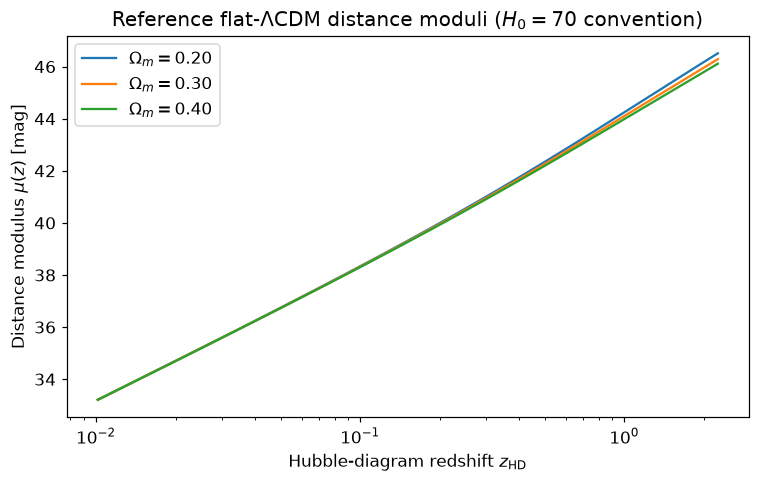

In [8]:
H0_CONVENTION = 70.0  # km/s/Mpc; NOT an estimate from these data
OMEGA_GRID = np.linspace(0.10, 0.60, 101)
C_LIGHT_KMS = 299792.458  # exactly defined speed of light in km/s
GL_X, GL_W = leggauss(48)  # quadrature nodes and weights, reused across all models

def mu_flat_lcdm(redshift, omega_m, H0=H0_CONVENTION):
    """Matter + Lambda, flat, no-radiation luminosity distance via quadrature.

    redshift must be > 0. Returns distance modulus in magnitudes.
    """
    redshift = np.asarray(redshift, dtype=float)
    if np.any(redshift <= 0) or not 0 <= omega_m <= 1:
        raise ValueError("Require redshift > 0 and 0 <= Omega_m <= 1")
    zp = redshift[..., None] * (GL_X + 1.0) / 2.0
    E = np.sqrt(omega_m * (1.0 + zp)**3 + (1.0 - omega_m))
    integral = redshift / 2.0 * np.sum(GL_W / E, axis=-1)
    d_l_mpc = (1.0 + redshift) * (C_LIGHT_KMS / H0) * integral
    return 5.0 * np.log10(d_l_mpc) + 25.0

# Independent numerical check at one redshift using adaptive integration.
z_check, om_check = 0.7, 0.3
integration, _ = quad(lambda zp: 1.0 / np.sqrt(om_check*(1+zp)**3 + 1-om_check),
                      0, z_check, epsrel=1e-11)
d_l_check = (1+z_check) * C_LIGHT_KMS/H0_CONVENTION * integration
mu_check = 5*np.log10(d_l_check) + 25
assert np.isclose(mu_flat_lcdm(z_check, om_check), mu_check, atol=1e-10)
print(f"Quadrature check at z={z_check}: mu={mu_check:.8f} mag (passed)")

z_display = np.geomspace(max(0.01, z.min()), z.max(), 300)
fig, ax = plt.subplots(figsize=(8, 4.5))
for om in (0.20, 0.30, 0.40):
    ax.plot(z_display, mu_flat_lcdm(z_display, om), label=rf"$\Omega_m={om:.2f}$")
ax.set(xscale="log", xlabel=r"Hubble-diagram redshift $z_{\rm HD}$",
       ylabel=r"Distance modulus $\mu(z)$ [mag]",
       title=r"Reference flat-$\Lambda$CDM distance moduli ($H_0=70$ convention)")
ax.legend()
plt.show()


### Exercise 2 — explain the physical sensitivity

**At fixed $H_0$, why do the curves for different $\Omega_m$ separate at higher redshift? At very low $z$, use the first-order expansion**

$$
D_L(z)\simeq \frac{cz}{H_0}
$$

**to explain why low-redshift data primarily constrain an *intercept* rather than the detailed shape of $E(z)$.**

**Record one limitation of using a simple flat-$\Lambda$CDM model as a teaching baseline.**

- At a fixed $H_0$, the curves separate at higher redshifts because different values of $\Omega_m$ affect how the Universe expands. This affects the predicted Luminosity distances. At very low redshifts, $D_L(z)\simeq \frac{cz}{H_0}$, so the distances depend mainly on $H_0$ and not on the $\Omega_m$. So high redshift observations provide more information about $\Omega_m$.

- One limitation is that the model assumes a flat Universe and constant dark energy.

## B2. Statistical observation model and identifiability

Pantheon+ gives standardized apparent magnitudes $m_{B,i}^{\rm corr}$, **not** directly measured distance moduli independent of calibration. We write

$$
\boxed{
m_{B,i}^{\mathrm{corr}}
=\mu(z_i;\Omega_m,H_0)+M_B+\epsilon_i
}
$$

with a *global* nuisance magnitude $M_B$ and correlated residuals

$$
\boldsymbol\epsilon\sim\mathcal N(\mathbf 0,\mathbf C).
$$

Since $D_L\propto H_0^{-1}$ when $\Omega_m$ is fixed,

$$
\mu(z;H_0')
=\mu(z;H_0)-5\log_{10}\!\left(\frac{H_0'}{H_0}\right).
$$

The same predicted apparent magnitude is obtained by shifting the nuisance parameter:

$$
\boxed{
M_B'=M_B+5\log_{10}\!\left(\frac{H_0'}{H_0}\right)
}
$$

Thus the supernova apparent-magnitude likelihood alone is unchanged by a simultaneous $(H_0,M_B)$ transformation: **$H_0$ and $M_B$ are not separately identifiable.** Fixing $H_0=70$ is only a zero-point convention, not an independent measurement of $H_0$.


## C1. Derive the correlated Gaussian likelihood, including its normalization

For the selected $n$ measurements, let

$$
\mathbf r(\Omega_m,M_B)
=\mathbf m_B^{\rm corr}
-\boldsymbol\mu(\Omega_m,H_0)
-M_B\mathbf 1.
$$

If $\mathbf C$ is known and positive definite, the multivariate Gaussian data density is

$$
\mathcal L(\Omega_m,M_B)
=\frac{1}{(2\pi)^{n/2}|\mathbf C|^{1/2}}
\exp\!\left[-\frac12\mathbf r^{\mathsf T}\mathbf C^{-1}\mathbf r\right].
$$

Taking the logarithm,

$$
\boxed{
-2\log\mathcal L
=\underbrace{\mathbf r^{\mathsf T}\mathbf C^{-1}\mathbf r}_{\chi^2}
+\log|\mathbf C|+n\log(2\pi)
}
$$

In **this** lab the covariance is held fixed as parameters vary, so the last two terms do not affect the maximum or the relative likelihood curve. If the covariance depends on $\Omega_m$ or a noise parameter, we must retain them.

**Computing rule:** Do not explicitly calculate $\mathbf C^{-1}$. First compute the Cholesky factorization $\mathbf C=\mathbf L\mathbf L^{\mathsf T}$ and solve the systems $\mathbf C\mathbf x=\mathbf r$.


## C2. Analytically eliminate the nuisance magnitude $M_B$

Define

$$
\mathbf y(\Omega_m)
=\mathbf m_B^{\rm corr}-\boldsymbol\mu(z;\Omega_m,H_0).
$$

Then

$$
\begin{aligned}
\chi^2(\Omega_m,M_B)
&=(\mathbf y-M_B\mathbf1)^{\mathsf T}
\mathbf C^{-1}(\mathbf y-M_B\mathbf1)\\
&=a-2bM_B+dM_B^2,
\end{aligned}
$$

where

$$
\begin{aligned}
a&=\mathbf y^{\mathsf T}\mathbf C^{-1}\mathbf y,\\
b&=\mathbf1^{\mathsf T}\mathbf C^{-1}\mathbf y,\\
d&=\mathbf1^{\mathsf T}\mathbf C^{-1}\mathbf1>0.
\end{aligned}
$$

Differentiate and set the derivative to zero:

$$
\frac{\partial\chi^2}{\partial M_B}
=-2b+2dM_B=0.
$$

Therefore the **conditional** maximum-likelihood nuisance estimate is

$$
\boxed{\widehat M_B(\Omega_m)=\frac{b}{d}}
$$

and the **profile chi-square** becomes

$$
\boxed{
\chi^2_{\rm prof}(\Omega_m)
=a-\frac{b^2}{d}
}
$$

The corresponding profile likelihood is $\mathcal L_{\rm prof}(\Omega_m)=\max_{M_B}\mathcal L(\Omega_m,M_B)$.

### Numerical-stability improvement

Because $M_B$ is near $-19$ mag, $a$ and $b^2/d$ can be much larger than their difference. Instead choose a nearby **fixed numerical pivot** $M_{\rm pivot}=-19.3$ and set

$$
\mathbf q=\mathbf m_B^{\rm corr}
-\boldsymbol\mu-M_{\rm pivot}\mathbf1.
$$

Define $A=\mathbf q^{\mathsf T}\mathbf C^{-1}\mathbf q$, $B=\mathbf1^{\mathsf T}\mathbf C^{-1}\mathbf q$, and the same $d$ as above. Then

$$
\boxed{
\begin{aligned}
\widehat M_B&=M_{\rm pivot}+\frac{B}{d},\\
\chi^2_{\rm prof}&=A-\frac{B^2}{d}.
\end{aligned}}
$$

This pivot is a computational device, **not a calibration prior**; a change in its value leaves the mathematical result invariant.


In [9]:
M_PIVOT = -19.3  # purely numerical pivot, no prior or external calibration

class ProfileMagnitudeLikelihood:
    """Compute a stable Gaussian SN likelihood profile at fixed covariance."""
    def __init__(self, z, m, C, H0=70.0, pivot=-19.3):
        self.z = np.asarray(z, float)
        self.m = np.asarray(m, float)
        self.C = np.asarray(C, float)
        self.H0 = float(H0)
        self.pivot = float(pivot)
        self.ones = np.ones(len(self.z))
        assert self.C.shape == (len(self.z), len(self.z))
        self.cf = cho_factor(self.C, lower=True, check_finite=True)
        self.Cinv_one = cho_solve(self.cf, self.ones)
        self.d = float(self.ones @ self.Cinv_one)
        assert self.d > 0

    def coefficients(self, omega_m):
        mu = mu_flat_lcdm(self.z, omega_m, self.H0)
        q = self.m - mu - self.pivot
        solve_q = cho_solve(self.cf, q)
        A = float(q @ solve_q)
        B = float(self.Cinv_one @ q)
        return A, B, self.d

    def evaluate(self, omega_m):
        A, B, d = self.coefficients(omega_m)
        mb_hat = self.pivot + B/d
        chi2_profile = A - B*B/d
        return mb_hat, chi2_profile

    def scan(self, omega_grid):
        values = np.array([self.evaluate(om) for om in omega_grid])
        return values[:, 0], values[:, 1]

likelihood = ProfileMagnitudeLikelihood(z, m, C, H0_CONVENTION, M_PIVOT)
t0 = time.perf_counter()
mb_hat_grid, chi2_grid = likelihood.scan(OMEGA_GRID)
print(f"Profile grid calculated in {time.perf_counter()-t0:.1f} s")

imin = int(np.argmin(chi2_grid))
OM_BEST = float(OMEGA_GRID[imin])
MB_BEST = float(mb_hat_grid[imin])
CHI2_MIN = float(chi2_grid[imin])
print(f"Grid MLE: Omega_m={OM_BEST:.5f}, M_B={MB_BEST:.5f} mag")
print(f"Min chi-square: {CHI2_MIN:.3f}")


Profile grid calculated in 0.7 s
Grid MLE: Omega_m=0.34500, M_B=-19.34614 mag
Min chi-square: 1470.531


### Exercise 3 — verify the analytic profile

**At one fixed $\Omega_m$, calculate the chi-square at $M_B=\widehat M_B$ using the *direct residual* and Cholesky solve. Show that it agrees with the analytic profiled value.**

**Then inspect a narrow curve of $\chi^2(M_B)$ on either side of $\widehat M_B$. Why must the curve be a parabola?**

The results that we obtained for a fixed $\Omega_m$ are
- Direct chi-square: 1470.5310955010557
- Profile chi-square: 1470.5310955010561

The values are practically identical, so the difference comes from numerical precision. This confirms that the analytical method gives the same result as calculating chi-square directly. 

Now about the graph, the minimum occurs at $\widehat{M}_B=-19.346$, and this is the best-fitting absolute magnitude for $\Omega_m$. The curve is a parabola because $M_B$ enteres the model linearly, while the chi-square depends on the squared residuals. So moving away from the best-fitting value increases chi-square quadratically. 

Direct chi-square: 1470.5310955010557
Profile chi-square: 1470.5310955010561


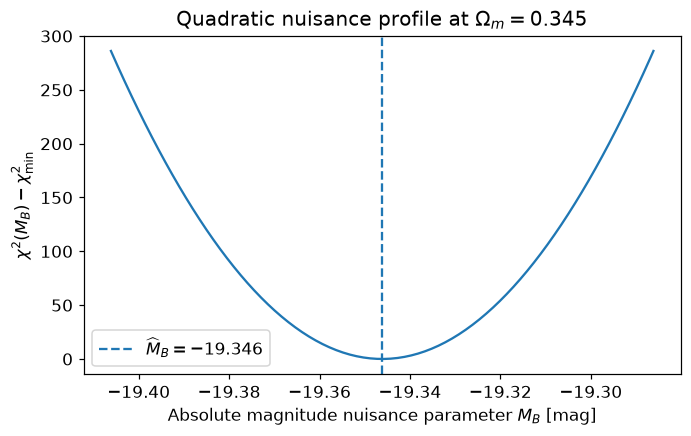

In [10]:
mu_best_grid = mu_flat_lcdm(z, OM_BEST, H0_CONVENTION)
r_best_grid = m - mu_best_grid - MB_BEST
chi2_direct = r_best_grid @ cho_solve(likelihood.cf, r_best_grid)
print("Direct chi-square:", chi2_direct)
print("Profile chi-square:", CHI2_MIN)
assert np.isclose(chi2_direct, CHI2_MIN, rtol=1e-8, atol=1e-6)

mb_view = MB_BEST + np.linspace(-0.06, 0.06, 160)
A, B, d = likelihood.coefficients(OM_BEST)
chi2_mb = A - 2*(mb_view - likelihood.pivot)*B + d*(mb_view - likelihood.pivot)**2
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mb_view, chi2_mb - CHI2_MIN)
ax.axvline(MB_BEST, ls="--", label=rf"$\widehat M_B={MB_BEST:.3f}$")
ax.set(xlabel=r"Absolute magnitude nuisance parameter $M_B$ [mag]",
       ylabel=r"$\chi^2(M_B)-\chi^2_{\rm min}$",
       title=rf"Quadratic nuisance profile at $\Omega_m={OM_BEST:.3f}$")
ax.legend()
plt.show()


## D1. Maximum-likelihood estimate and the profile curve

Because the covariance is fixed, the relative profile likelihood obeys

$$
\frac{\mathcal L_{\rm prof}(\Omega_m)}{\mathcal L_{\rm prof}(\widehat\Omega_m)}
=\exp\left[-\frac12\Delta\chi^2(\Omega_m)\right],
$$

where

$$
\boxed{
\Delta\chi^2(\Omega_m)
=\chi^2_{\rm prof}(\Omega_m)-\chi^2_{\rm prof}(\widehat\Omega_m).
}
$$

For one regular interior parameter, the conventional approximate 68% **profile-likelihood interval** is bounded by $\Delta\chi^2=1$. This follows from an asymptotic likelihood-ratio approximation (Wilks' theorem); it is **not** automatically exact in small samples, at boundaries or under model misspecification.

We interpolate each crossing rather than reporting the coarsest grid point inside the interval.


Approximate 68% profile-likelihood interval: [0.3337, 0.3599]


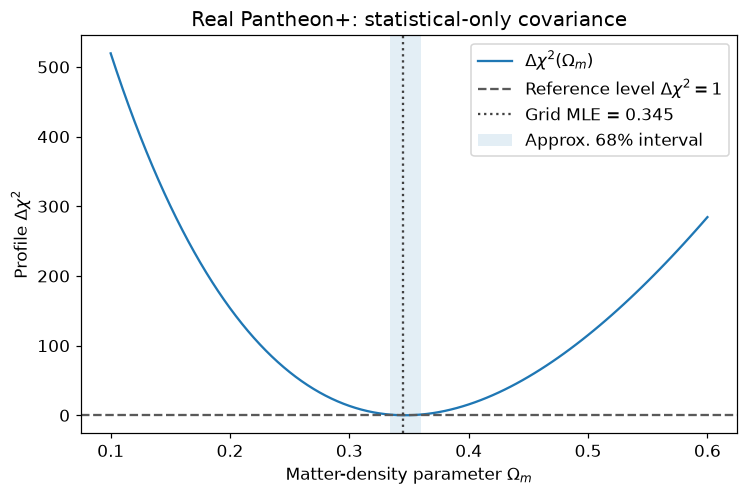

In [11]:
def delta_chi2_crossings(grid, chi2, target=1.0):
    """Linearly interpolate the crossings nearest the global grid minimum."""
    grid = np.asarray(grid, float)
    chi2 = np.asarray(chi2, float)
    i0 = int(np.argmin(chi2))
    delta = chi2 - chi2[i0]
    # Search outward from the minimum for the first crossing on each side.
    left = right = np.nan
    for i in range(i0 - 1, -1, -1):
        if delta[i] >= target and delta[i+1] < target:
            left = float(np.interp(target, [delta[i+1], delta[i]],
                                   [grid[i+1], grid[i]]))
            break
    for i in range(i0 + 1, len(grid)):
        if delta[i] >= target and delta[i-1] < target:
            right = float(np.interp(target, [delta[i-1], delta[i]],
                                    [grid[i-1], grid[i]]))
            break
    return left, right

DELTA = chi2_grid - CHI2_MIN
left_68, right_68 = delta_chi2_crossings(OMEGA_GRID, chi2_grid)
print(f"Approximate 68% profile-likelihood interval: [{left_68:.4f}, {right_68:.4f}]")
if not (np.isfinite(left_68) and np.isfinite(right_68)):
    print("One or both crossings are beyond the scanned range; broaden the grid.")

fig, ax = plt.subplots(figsize=(7.7, 4.7))
ax.plot(OMEGA_GRID, DELTA, label=r"$\Delta\chi^2(\Omega_m)$")
ax.axhline(1.0, color="0.35", ls="--", label=r"Reference level $\Delta\chi^2=1$")
ax.axvline(OM_BEST, color="0.25", ls=":", label=rf"Grid MLE = {OM_BEST:.3f}")
if np.isfinite(left_68) and np.isfinite(right_68):
    ax.axvspan(left_68, right_68, alpha=0.12, label="Approx. 68% interval")
ax.set(xlabel=r"Matter-density parameter $\Omega_m$",
       ylabel=r"Profile $\Delta\chi^2$",
       title="Real Pantheon+: statistical-only covariance")
ax.legend()
plt.show()


### Numerical caution — why we avoid unstable subtraction

A direct polynomial in $M_B\simeq-19$ can involve cancellations between terms of order millions and a final $\chi^2$ of order thousands. The fixed pivot in the previous section reduces cancellation.

A second improvement is to locate the profile minimum using a **bounded scalar optimizer** and evaluate its confidence crossings with a root finder. Here we first demonstrate the optimizer, then retain the grid for visualization and reproducibility.


In [12]:
fit = minimize_scalar(
    lambda om: likelihood.evaluate(om)[1],
    bounds=(float(OMEGA_GRID[0]), float(OMEGA_GRID[-1])),
    method="bounded",
    options={"xatol": 1e-6},
)
assert fit.success
OM_OPT = float(fit.x)
MB_OPT, CHI2_OPT = likelihood.evaluate(OM_OPT)
print(f"Continuous optimizer: Omega_m={OM_OPT:.6f}, M_B={MB_OPT:.5f}")
print(f"Grid minus continuous chi-square: {CHI2_MIN - CHI2_OPT:.5g}")
assert CHI2_OPT <= CHI2_MIN + 1e-4


Continuous optimizer: Omega_m=0.346580, M_B=-19.34561
Grid minus continuous chi-square: 0.014573


### Exercise 4 — grid resolution and interval interpretation

**Results**

Grid points: **101**
- Best Omega_m: 0.34500
- 68% interval: [0.33368, 0.35986]

Grid points: **51**
- Best Omega_m: 0.35000
- 68% interval: [0.33411, 0.36017]

Grid points: **201**
- Best Omega_m: 0.34750
- 68% interval: [0.33362, 0.35980]

Continuous optimizer: Omega_m=0.346580, M_B=-19.34561

Grid minus continuous chi-square: 0.014573

**1. Change the number of $\Omega_m$ grid points from 101 to 51, then to 201. Does the point estimate or interpolated interval change appreciably?**
- We changed the number of grid points from 51 to 101 and 201, and they slightly changed. The interpolated intervals remain almost the same. So we can imply that our results are stable and do not depend significantly on the grid resolution. 

**2. Compare the grid MLE with the bounded optimizer.**
- The Continous optimizer gives a best fitting value of Omega_m=0.346580, which is very close to the values obtained with the different grids. The difference of chi squared is also small, showing that the grid estimate is close to the continous minimum.
- These differences may be becuase the grid only evaluates specific values while the continuos optimizer actually can search between them. 

**3. If a crossing lies beyond the scanned domain, report it as *unresolved* rather than inventing an endpoint.**
- If its outside the scanned domain, it should be report as unresolved because we cannot determine its value from the available grid. In our case both crossings are within the range so the interval is resolved. 

**4. Explain why $\Delta\chi^2\le1$ should not be called a Bayesian credible interval.**
- The interval defined by $\Delta\chi^2\le1$ is an approximate 68% frequentist confidence interval for one parameter, not a Bayesian interval. For a Bayesian credible interval we need a posterior, which depends on the likelihood and the prior. Since we are using the chi squared, we do not calculate the posterior. 


Quadrature check at z=0.7: mu=43.14689580 mag (passed)


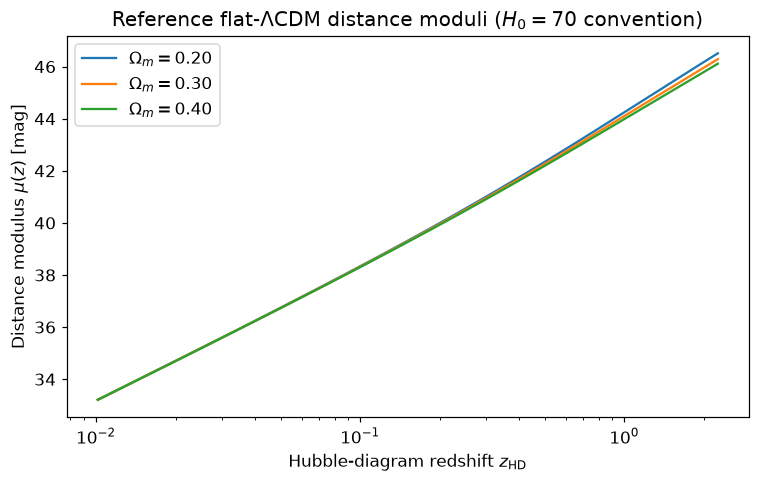

In [20]:
H0_CONVENTION = 70.0  # km/s/Mpc; NOT an estimate from these data
OMEGA_GRID = np.linspace(0.10, 0.60, 101)
C_LIGHT_KMS = 299792.458  # exactly defined speed of light in km/s
GL_X, GL_W = leggauss(48)  # quadrature nodes and weights, reused across all models

def mu_flat_lcdm(redshift, omega_m, H0=H0_CONVENTION):
    """Matter + Lambda, flat, no-radiation luminosity distance via quadrature.

    redshift must be > 0. Returns distance modulus in magnitudes.
    """
    redshift = np.asarray(redshift, dtype=float)
    if np.any(redshift <= 0) or not 0 <= omega_m <= 1:
        raise ValueError("Require redshift > 0 and 0 <= Omega_m <= 1")
    zp = redshift[..., None] * (GL_X + 1.0) / 2.0
    E = np.sqrt(omega_m * (1.0 + zp)**3 + (1.0 - omega_m))
    integral = redshift / 2.0 * np.sum(GL_W / E, axis=-1)
    d_l_mpc = (1.0 + redshift) * (C_LIGHT_KMS / H0) * integral
    return 5.0 * np.log10(d_l_mpc) + 25.0

# Independent numerical check at one redshift using adaptive integration.
z_check, om_check = 0.7, 0.3
integration, _ = quad(lambda zp: 1.0 / np.sqrt(om_check*(1+zp)**3 + 1-om_check),
                      0, z_check, epsrel=1e-11)
d_l_check = (1+z_check) * C_LIGHT_KMS/H0_CONVENTION * integration
mu_check = 5*np.log10(d_l_check) + 25
assert np.isclose(mu_flat_lcdm(z_check, om_check), mu_check, atol=1e-10)
print(f"Quadrature check at z={z_check}: mu={mu_check:.8f} mag (passed)")

z_display = np.geomspace(max(0.01, z.min()), z.max(), 300)
fig, ax = plt.subplots(figsize=(8, 4.5))
for om in (0.20, 0.30, 0.40):
    ax.plot(z_display, mu_flat_lcdm(z_display, om), label=rf"$\Omega_m={om:.2f}$")
ax.set(xscale="log", xlabel=r"Hubble-diagram redshift $z_{\rm HD}$",
       ylabel=r"Distance modulus $\mu(z)$ [mag]",
       title=r"Reference flat-$\Lambda$CDM distance moduli ($H_0=70$ convention)")
ax.legend()
plt.show()

In [21]:
# Exercise 4 - Grid resolution comparison

for n in [101, 51, 201]:
    omega_grid = np.linspace(0.10, 0.60, n)

    mb_grid, chi2_grid_test = likelihood.scan(omega_grid)

    i_min = np.argmin(chi2_grid_test)
    omega_best = omega_grid[i_min]

    left, right = delta_chi2_crossings(omega_grid, chi2_grid_test)

    print(f"Grid points: {n}")
    print(f"Best Omega_m: {omega_best:.5f}")
    print(f"68% interval: [{left:.5f}, {right:.5f}]")
    print()

Grid points: 101
Best Omega_m: 0.34500
68% interval: [0.33368, 0.35986]

Grid points: 51
Best Omega_m: 0.35000
68% interval: [0.33411, 0.36017]

Grid points: 201
Best Omega_m: 0.34750
68% interval: [0.33362, 0.35980]



## D2. Likelihood geometry: two parameters before profiling

The two-dimensional likelihood surface can be reconstructed at any chosen $(\Omega_m,M_B)$ using the quadratic expansion around $M_{\rm pivot}$:

$$
\chi^2(\Omega_m,M_B)
=A(\Omega_m)-2B(\Omega_m)(M_B-M_{\rm pivot})
+d(M_B-M_{\rm pivot})^2.
$$

A long, tilted valley indicates nuisance–cosmology coupling. The profile curve follows the bottom of that valley.


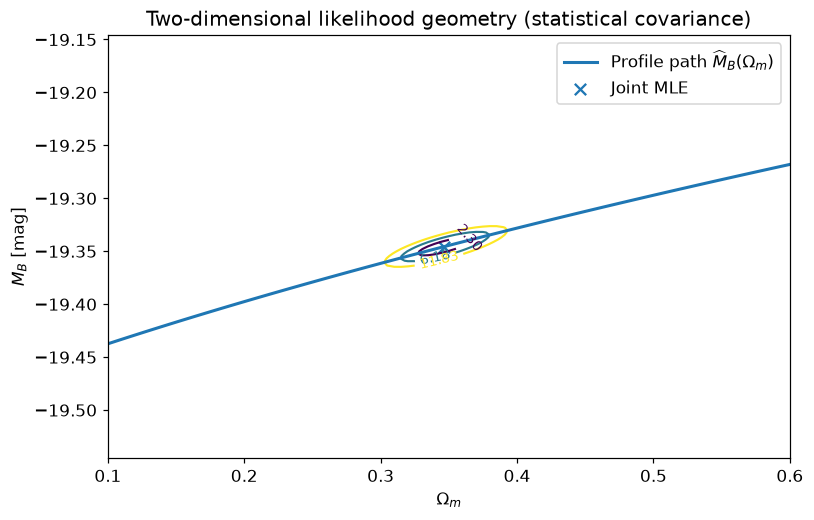

In [22]:
MB_VIEW_GRID = MB_OPT + np.linspace(-0.20, 0.20, 181)
coefficients = np.array([likelihood.coefficients(om) for om in OMEGA_GRID])
AA, BB, DD = coefficients[:,0], coefficients[:,1], coefficients[:,2]
dmb = MB_VIEW_GRID[None,:] - M_PIVOT
CHI2_SURFACE = AA[:,None] - 2*BB[:,None]*dmb + DD[:,None]*dmb**2

fig, ax = plt.subplots(figsize=(8, 5))
levels = [2.30, 6.18, 11.83]  # approximate two-parameter likelihood ratio references
cs = ax.contour(OMEGA_GRID, MB_VIEW_GRID,
                (CHI2_SURFACE - CHI2_OPT).T,
                levels=levels, linewidths=1.4)
ax.clabel(cs, inline=True, fontsize=9)
ax.plot(OMEGA_GRID, mb_hat_grid, lw=2, label=r"Profile path $\widehat M_B(\Omega_m)$")
ax.scatter([OM_OPT], [MB_OPT], s=55, marker="x", label="Joint MLE")
ax.set(xlabel=r"$\Omega_m$", ylabel=r"$M_B$ [mag]",
       title="Two-dimensional likelihood geometry (statistical covariance)")
ax.legend()
plt.show()


## E1. Test a fundamental degeneracy: change the fixed $H_0$ convention

For $H_0'=73$ km s$^{-1}$ Mpc$^{-1}$, the expected nuisance-magnitude displacement is

$$
\boxed{
\Delta M_B=5\log_{10}\!\left(\frac{73}{70}\right)
}
$$

If $M_B$ is freely profiled and the covariance is fixed, then **every value of $\chi^2_{\rm prof}(\Omega_m)$ should remain invariant**, not merely the minimum. Consequently $\widehat\Omega_m$ should remain invariant as well (up to numerical tolerance).


Analytic M_B shift when H0: 70 -> 73 = +0.091124 mag
Median recovered M_B shift: 0.09112410053099396
Max |difference in profile chi-square|: 6.59383658785373e-12


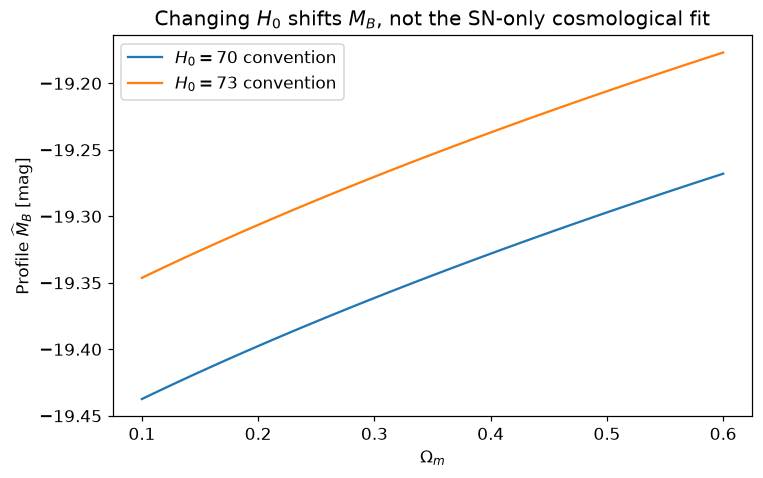

In [14]:
H0_ALTERNATIVE = 73.0
likelihood_73 = ProfileMagnitudeLikelihood(z, m, C, H0_ALTERNATIVE, M_PIVOT)
mb_grid_73, chi2_grid_73 = likelihood_73.scan(OMEGA_GRID)
expected_shift = 5.0 * np.log10(H0_ALTERNATIVE / H0_CONVENTION)

print(f"Analytic M_B shift when H0: 70 -> 73 = {expected_shift:+.6f} mag")
print("Median recovered M_B shift:", np.median(mb_grid_73 - mb_hat_grid))
print("Max |difference in profile chi-square|:", np.max(np.abs(chi2_grid_73 - chi2_grid)))

assert np.allclose(mb_grid_73 - mb_hat_grid, expected_shift, atol=2e-5)
assert np.allclose(chi2_grid_73, chi2_grid, atol=2e-4)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(OMEGA_GRID, mb_hat_grid, label=r"$H_0=70$ convention")
ax.plot(OMEGA_GRID, mb_grid_73, label=r"$H_0=73$ convention")
ax.set(xlabel=r"$\Omega_m$", ylabel=r"Profile $\widehat M_B$ [mag]",
       title=r"Changing $H_0$ shifts $M_B$, not the SN-only cosmological fit")
ax.legend()
plt.show()


### Exercise 5 — interpret the non-identifiability test

**Describe the difference between *fixing a parameter by convention* and *constraining it with data*. Explain in 100–150 words why it would be scientifically incorrect to claim that this lab measured $H_0$.**

Fixing a parameter by convention means that we choose a value before performing the analysis. While constraining a parameter means estimating its value using observational data. In the lab we fixed the value of H0 instead of estimating it from the supernova observations. We used the data to constrain Omega_m and fitted M_B. 

The issue is that both H0 and M_B are degenerate, which means that if we change one value it can be compensated by changing the other. This produces the same predicted apparent magnitudes. So the observations cannot distinguish between the compinations of the parameters. It is incorrect to claim that we measure H0 because of this reason, we only assumed its value. 


**Advanced check: Show algebraically why the alternative $M_B'$ transformation leaves the predicted magnitude $\mu(z;H_0')+M_B'$ unchanged at every redshift.**


From the notebook, we define the flat $\Lambda$CDM model:

$$
D_L(z;\Omega_m,H_0)=(1+z)\frac{c}{H_0}
\int_0^z\frac{dz'}{E(z';\Omega_m)}
$$

Since $H_0$ appears in the denominator, changing it to $H_0'$ gives:

$$
D_L(z;\Omega_m,H_0')
=
\frac{H_0}{H_0'}D_L(z;\Omega_m,H_0)
$$

Next using the distance modulus defined in the notebook:

$$
\mu(z)=5\log_{10}\left(\frac{D_L(z)}{\mathrm{Mpc}}\right)+25
$$, 

We substitute the new luminoisty distance from above and we get: 

$$
\mu(z;H_0')
=
5\log_{10}\left(
\frac{H_0}{H_0'}
\frac{D_L(z;\Omega_m,H_0)}{\mathrm{Mpc}}
\right)+25
$$

Using the logarithm property:

$$
\mu(z;H_0')
=
\mu(z;H_0)+5\log_{10}\left(\frac{H_0}{H_0'}\right)
$$


To compensate for the change in $H_0$, we define the new M_B':

$$
M_B'=M_B+5\log_{10}\left(\frac{H_0'}{H_0}\right)
$$

Next we substitute both expressions into the predicted magnitude:

$$
\mu(z;H_0')+M_B'
=
\left[\mu(z;H_0)+5\log_{10}\left(\frac{H_0}{H_0'}\right)\right]
+\left[M_B+5\log_{10}\left(\frac{H_0'}{H_0}\right)\right]
$$

the logarithmic terms cancel:

$$
\log_{10}\left(\frac{H_0}{H_0'}\right)
+
\log_{10}\left(\frac{H_0'}{H_0}\right)=0
$$

Our final result is given by, 

$$
\mu(z;H_0')+M_B'=\mu(z;H_0)+M_B
$$

These parameters cannot be independently constrained using these supernova observations alone.

## F1. Residual analysis and goodness-of-fit diagnostics

At the joint maximum, the magnitude residual vector is

$$
\boxed{
\widehat{\mathbf r}=
\mathbf m_B^{\rm corr}
-\boldsymbol\mu(z;\widehat\Omega_m,H_0)
-\widehat M_B\mathbf1
}
$$

Two different notions of standardization are useful:

1. **Per-row scaling:** $s_i=\widehat r_i/\sqrt{C_{ii}}$, useful for plotting against $z$, but the resulting entries are generally *correlated*.
2. **Cholesky whitening:** if $\mathbf C=\mathbf L\mathbf L^{\mathsf T}$, then $\mathbf w=\mathbf L^{-1}\widehat{\mathbf r}$ has identity covariance *before accounting for fitted parameters*, under the assumed Gaussian model. The order-dependent whitening transform mixes rows, so $w_i$ is **not** the residual of a single supernova at redshift $z_i$.

Do not use the diagonal plotting uncertainties to calculate the likelihood.


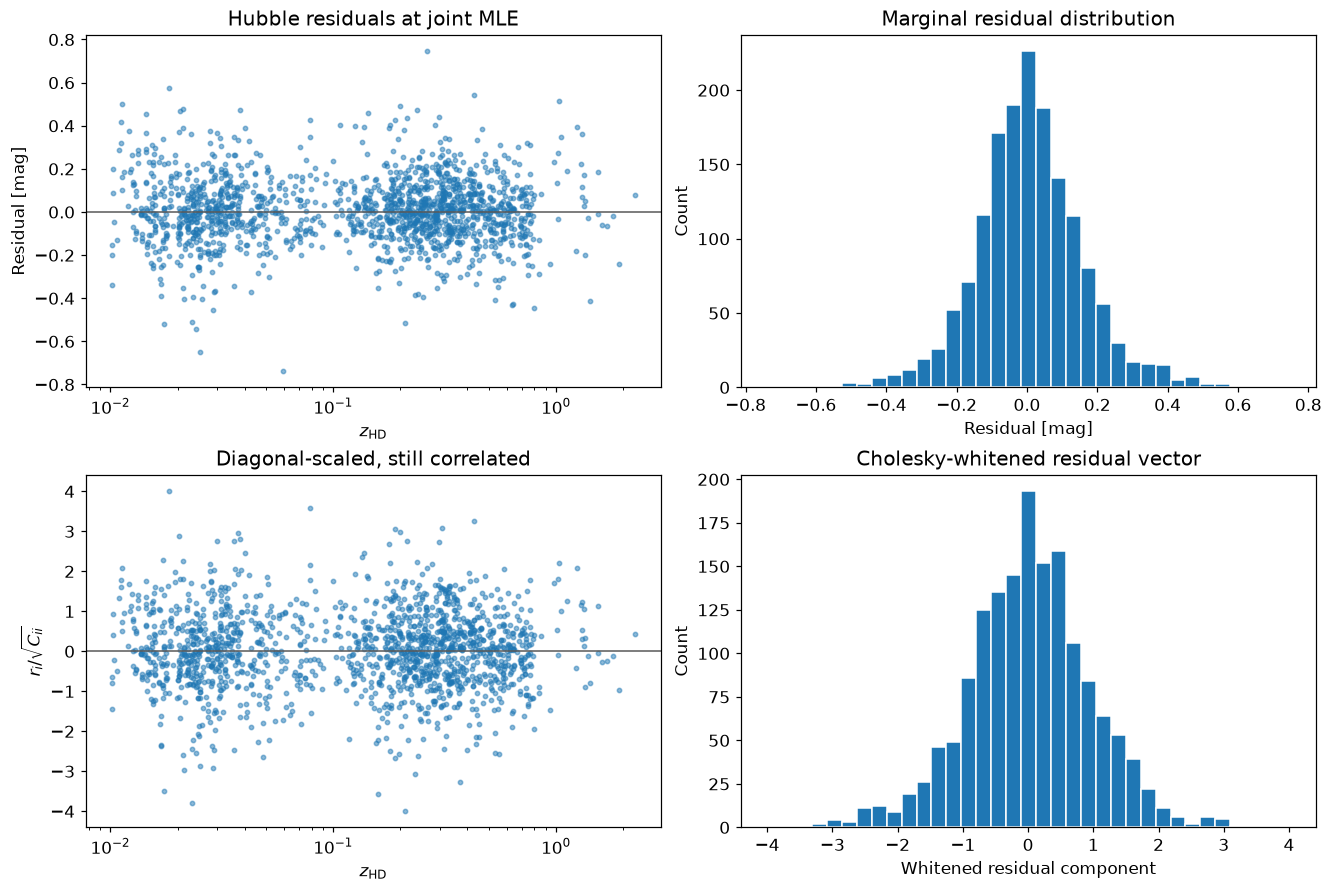

Norm of whitened residuals squared: 1470.5165221882933
Direct full-covariance chi-square: 1470.5165221882933


In [15]:
mu_opt = mu_flat_lcdm(z, OM_OPT, H0_CONVENTION)
residuals = m - mu_opt - MB_OPT
scaled_residuals = residuals / np.sqrt(np.diag(C))
L = np.tril(likelihood.cf[0])
whitened = solve_triangular(L, residuals, lower=True, check_finite=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes[0,0].scatter(z, residuals, s=8, alpha=0.5)
axes[0,0].axhline(0, color="0.35", lw=1)
axes[0,0].set(xscale="log", xlabel=r"$z_{\rm HD}$", ylabel="Residual [mag]",
              title="Hubble residuals at joint MLE")
axes[0,1].hist(residuals, bins=35, edgecolor="white")
axes[0,1].set(xlabel="Residual [mag]", ylabel="Count", title="Marginal residual distribution")
axes[1,0].scatter(z, scaled_residuals, s=8, alpha=0.5)
axes[1,0].axhline(0, color="0.35", lw=1)
axes[1,0].set(xscale="log", xlabel=r"$z_{\rm HD}$",
              ylabel=r"$r_i/\sqrt{C_{ii}}$", title="Diagonal-scaled, still correlated")
axes[1,1].hist(whitened, bins=35, edgecolor="white")
axes[1,1].set(xlabel="Whitened residual component", ylabel="Count",
              title="Cholesky-whitened residual vector")
plt.show()

print("Norm of whitened residuals squared:", whitened @ whitened)
print("Direct full-covariance chi-square:", residuals @ cho_solve(likelihood.cf, residuals))
assert np.isclose(whitened @ whitened,
                  residuals @ cho_solve(likelihood.cf, residuals), rtol=1e-7)


## F2. Methodological stress test — covariance is a scientific choice

A **diagonal-only** approximation discards the correlations in $\mathbf C$. Here we calculate it as a diagnostic comparison, **not** as the adopted cosmological result.

With diagonal covariance, the quadratic form would be

$$
\chi^2_{\rm diag}
=\sum_{i=1}^{n}\frac{r_i^2}{C_{ii}}.
$$

Compare its profile curve with the properly correlated analysis. A seemingly more precise diagonal-only curve is not automatically a better or more reliable inference.


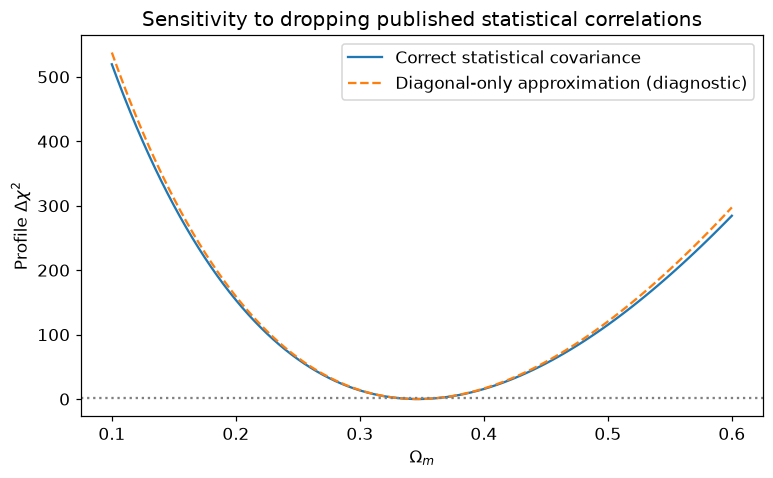

In [16]:
weights = 1.0 / np.diag(C)
def diagonal_profile(omega_m, H0=H0_CONVENTION):
    q = m - mu_flat_lcdm(z, omega_m, H0) - M_PIVOT
    D = weights.sum()
    B = np.dot(weights, q)
    A = np.dot(weights, q*q)
    return M_PIVOT + B/D, A - B*B/D

chi2_diag_grid = np.array([diagonal_profile(om)[1] for om in OMEGA_GRID])
delta_diag = chi2_diag_grid - chi2_diag_grid.min()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(OMEGA_GRID, chi2_grid - chi2_grid.min(), label="Correct statistical covariance")
ax.plot(OMEGA_GRID, delta_diag, ls="--", label="Diagonal-only approximation (diagnostic)")
ax.axhline(1.0, color="0.5", ls=":")
ax.set(xlabel=r"$\Omega_m$", ylabel=r"Profile $\Delta\chi^2$",
       title="Sensitivity to dropping published statistical correlations")
ax.legend()
plt.show()


### Optional extension — statistical versus statistical+systematic covariance

For a stronger research discussion, repeat **only if time and memory permit** using the official `Pantheon+SH0ES_STAT+SYS.cov`, keeping the same selected row indices. The full matrix is a separate ~33 MB download and is not silently substituted in the core exercise.

Be careful: the present notebook is a pedagogical subset and a deliberately simplified likelihood, **not** an official Pantheon+ parameter-reproduction pipeline. A systematic covariance comparison here shows sensitivity of this *particular educational analysis*, not a final cosmological result.


In [24]:
# Optional extension; remove the comment on the next line to run.
C_all_full = load_covariance(URL_FULL, "Pantheon+SH0ES_STAT+SYS.cov")
_, C_full, _ = subset_with_covariance(sn, C_all_full, mask)
full_model = ProfileMagnitudeLikelihood(z, m, C_full, H0_CONVENTION, M_PIVOT)
mb_full, chi2_full = full_model.scan(OMEGA_GRID)
print("Full covariance grid MLE:", OMEGA_GRID[np.argmin(chi2_full)])


Full covariance grid MLE: 0.33


**Analysis:** It changed the best fitting from 0.345 to 0.330. So this shows that the covariance matriz affects the estimate, but we cannot determine if this is significant without comparing the uncertainties. 

## F3. Final in-class checkpoint: evidence, not just numbers

**Show your instructor:**

1. Number of observed table rows and unique `CID` objects, plus the covariance dimension check.
2. Full-covariance $\Delta\chi^2(\Omega_m)$ plot with interpolated $\Delta\chi^2=1$ boundaries or an explicit warning if not bracketed.
3. $M_B$ profile and the two-dimensional likelihood geometry.
4. Numerical comparison of $H_0=70$ and $H_0=73$, including the predicted magnitude shift.
5. Residual versus redshift, residual histogram, and explanation of correlated versus whitened residuals.
6. A clearly labeled *diagnostic* comparison between diagonal-only and correlated covariance.

### Final scientific response (150–250 words)

**Explain what parameters were estimated, under what modeling assumptions, why the fitted $M_B$ is convention-dependent, what the covariance contributes, and what cannot be inferred from this exercise.**

In this lab, we used Supernova Type Ia from the Pantheon+ catalogue to estimate the matter density parameter ($\Omega_m$) under the assumptions of a flat $\Lambda$CDM cosmological model. We fixed the Hubble constant ($H_0$) to 70  km/s/Mpc and fitted the absolute magnitude $M_B$ as a nuisance parameter.

We obtained the best fitting value of $\Omega_m=0.345$ and $M_B=-19.346$ mag. The matrix takes into account uncertainties and correlations between the observations, which are important to obtain reliable estimates and intervals. 

The fitted value $M_B$ depends on our value $H_0$ becuase as mentioned, they are degenerate. So if we change $H_0$, it can be compensated by changing $M_B$, this will produce the same predicted apparent magnitudes. So we cannot independently measure $H_0$ from these observations without external calibration. 

We also did the optional assignment, where we compared the statistical covariance with the statistical and systematic covariance. We obtined $\Omega_m=0.330$, which shows that the treatment of the uncertainties affect our results. 

Finally, our esstimates depend on the assumptions of the $\Lambda$CDM model and the simplified likelihood used. So they should not be interpreted as official cosmological constraints of our database. 


Complete the sentence:

> “From these apparent magnitudes and a fixed-$H_0$ convention, we can constrain ___ **$\Omega_m$**___ under ___ **flat $\Lambda$CDM**___ assumptions, but without external calibration we cannot determine ___ **$H_0$**___.”


**Submission:** restart the kernel and execute all core cells in order; keep your explanations directly beneath the relevant exercises. Do not substitute synthetic supernovae for missing catalogue files.


## Bridge to Lab 04 — profiling is not Bayesian marginalization

The operation used today was **profiling**:

$$
\boxed{\mathcal L_{\rm prof}(\Omega_m)=\max_{M_B}\mathcal L(\Omega_m,M_B).}
$$

Next week we will compute the posterior by combining a likelihood and a prior, and then **marginalize** the nuisance parameter:

$$
\boxed{
p(\Omega_m\mid D)
=\int p(\Omega_m,M_B\mid D)\,dM_B.
}
$$

A useful mathematical result: for a parameter-independent covariance and an *improperly flat, unbounded* nuisance-magnitude weight,

$$
\int_{-\infty}^{\infty}
\exp\!\left[-\frac12\chi^2(\Omega_m,M_B)\right]\,dM_B
=\sqrt{\frac{2\pi}{d}}
\exp\!\left[-\frac12\chi^2_{\rm prof}(\Omega_m)\right].
$$

Thus, when $d$ is constant, the marginalized likelihood has the **same $\Omega_m$ shape** as the profile likelihood, up to normalization. Proper bounded/nonuniform priors, variable covariance, or more complex nuisance parameters can break this agreement.

### References

- <https://github.com/PantheonPlusSH0ES/DataRelease> — official table/covariance and README.
- Scolnic et al. (2022), *The Pantheon+ Analysis: The Full Data Set and Light-curve Release*, ApJ 938, 113; arXiv:2112.03863.
- Brout et al. (2022), *The Pantheon+ Analysis: Cosmological Constraints*, ApJ 938, 110; arXiv:2202.04077.
- Astropy documentation: [`FlatLambdaCDM`](https://docs.astropy.org/en/stable/api/astropy.cosmology.FlatLambdaCDM.html).
